# 01 Look at the data

Before I train anything I want to know what is in the file: how big it is, what the numbers mean, and how many
wafers there are of each defect. This notebook only looks, it doesn't change or save anything.

## 1. Open the file

The file holds two arrays: `arr_0` are the wafer maps (pictures of 52 by 52 squares) and `arr_1` are the labels
(8 numbers per wafer, one per defect).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import wafer # my own wafer.py, has the defect names and label_name()

data = np.load("../data/Wafer_Map_Datasets.npz") # npz = a few arrays in 1 file, opens like a dictionary
maps = data["arr_0"] # the wafer pictures
labels = data["arr_1"] # the 8 zeros/ones per wafer

# shape = the size of the array, (wafers, 52, 52) for the maps
print("Maps:", maps.shape)
print("Labels:", labels.shape)

Maps: (38015, 52, 52)
Labels: (38015, 8)


**What to look for:** the same number of maps and labels, every map 52 by 52, every label 8 long.

## 2. What do the numbers in a map mean?

The description says 0 is no chip, 1 is a good chip and 2 is a failed chip. Let me count what is really there.

In [2]:
# unique gives every value that shows up once, return_counts also counts how often
values, counts = np.unique(maps, return_counts=True)
for v, c in zip(values, counts): # zip = walk through both lists at the same time
    print(f"value {v}: {c:,} squares") # :, puts commas in big numbers

value 0: 24,349,490 squares
value 1: 53,392,308 squares
value 2: 25,050,548 squares
value 3: 214 squares


**What to look for:** a value 3 shows up, which the description doesn't mention. I take those wafers out in 02.

## 3. What does a label mean?

Each of the 8 positions is one defect: 1 means it is on the wafer, 0 means it isn't. All zeros is a Normal wafer.

In [3]:
# a few random wafers, to see what a label looks like next to its name
for i in [0, 5000, 20000, 35000]:
    print(labels[i], "->", wafer.label_name(labels[i]))

[1 0 1 0 0 0 1 0] -> Center + Edge-Loc + Scratch
[1 0 1 0 1 0 1 0] -> Center + Edge-Loc + Loc + Scratch
[0 1 0 1 1 0 0 0] -> Donut + Edge-Ring + Loc
[0 0 0 0 0 1 0 0] -> Near-Full


## 4. How many wafers of each defect?

A model learns less about a defect it rarely sees, so I count them.

In [4]:
for i in range(8):
    count = labels[:, i].sum() # [:, i] = column i for every wafer, sum = how many have that defect
    print(f"{wafer.DEFECTS[i]}: {count:,} wafers")

types = np.unique(labels, axis=0) # axis=0 so it compares whole labels, not single numbers
print()
print("Different combinations (types):", len(types))

Center: 13,000 wafers
Donut: 12,000 wafers
Edge-Loc: 13,000 wafers
Edge-Ring: 12,000 wafers
Loc: 18,000 wafers
Near-Full: 149 wafers
Scratch: 19,000 wafers
Random: 866 wafers

Different combinations (types): 38


**What to look for:** Near-Full and Random are much rarer than the rest. There are 38 different combinations, from Normal to
four defects at once.

## 5. Are there wafers in the file twice?

If the same map is in training and in the test, the test would make no sense. So I check for copies.

In [5]:
flat = maps.reshape(len(maps), -1) # every map as 1 long row so i can compare whole maps. -1 = figure out the length yourself
different = len(np.unique(flat, axis=0))
print(f"Maps: {len(maps):,}, different maps: {different:,}, copies: {len(maps) - different:,}")

Maps: 38,015, different maps: 36,991, copies: 1,024


## 6. What do the defects look like?

One wafer for each defect, with only that defect on it.

[1. 0. 0. 0. 0. 0. 0. 0.]
1.0
[0. 1. 0. 0. 0. 0. 0. 0.]
1.0
[0. 0. 1. 0. 0. 0. 0. 0.]
1.0
[0. 0. 0. 1. 0. 0. 0. 0.]
1.0
[0. 0. 0. 0. 1. 0. 0. 0.]
1.0
[0. 0. 0. 0. 0. 1. 0. 0.]
1.0
[0. 0. 0. 0. 0. 0. 1. 0.]
1.0
[0. 0. 0. 0. 0. 0. 0. 1.]
1.0


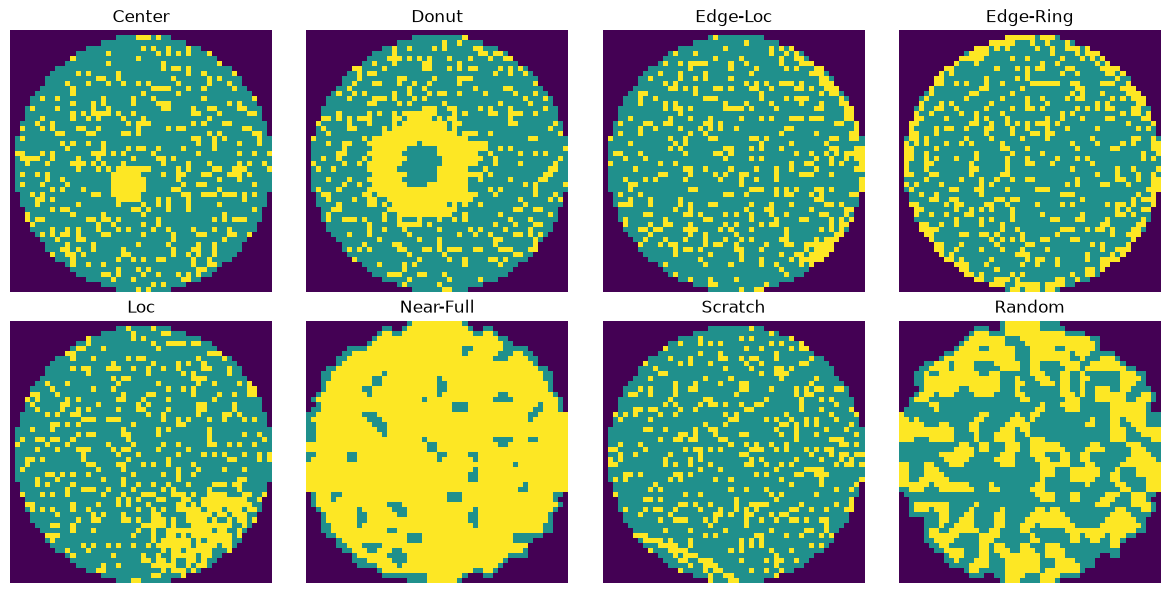

In [6]:
plt.figure(figsize=(12, 6))
for i in range(8):
    only_this = np.zeros(8)
    only_this[i] = 1 # a label with only this defect
    print(only_this)
    print(only_this[i])
    # .all(axis=1) = all 8 match, np.where gives the positions (in a tuple so [0]), last [0] = the first one
    first = np.where((labels == only_this).all(axis=1))[0][0]

    plt.subplot(2, 4, i + 1) # 2 rows 4 pics, counts from 1
    plt.imshow(maps[first]) # numbers -> colours
    plt.title(wafer.DEFECTS[i])
    plt.axis("off") # no numbers around it
plt.tight_layout()
plt.show()